## Config

### Imports

In [1]:
import os
import math
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display
import seaborn as sns

### loading data

In [2]:
data_path = os.path.join("data", "output", "projetos_2025_2026.csv")
df = pd.read_csv(data_path, sep=";", encoding='utf-8-sig')
print(df.shape)
df.head()

(53, 24)


,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,qtd_doutorado,total_alunos,edital_ou_chamada,coordenador,financiador,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,4430958315746203,Ivan do Carmo Machado,2024,NaN,Uma Investigação Empírica da Relação entre Ref...,Descrição: A temática de refatoração tem sido ...,Em andamento,Pesquisa,Mestrado acadêmico: (3) Doutorado: (4),Ivan do Carmo Machado - Coordenador / Carla Il...,...,4,7,Situação: Em andamento; Natureza: Pesquisa,Ivan do Carmo Machado,['Conselho Nacional de Desenvolvimento Científ...,Visualização de Dados e Processamento de Imagens,Refatoração de Testes,"['refatoração', 'teste de software', 'qualidad...",False,Este projeto investigará a refatoração de test...
1,4430958315746203,Ivan do Carmo Machado,2024,NaN,Consolidação da Rede Internacional de Pesquisa...,Descrição: O objetivo do projeto é promover a ...,Em andamento,Pesquisa,Mestrado acadêmico: (26) Doutorado: (26),Ivan do Carmo Machado - Integrante / Climene L...,...,26,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4430958315746203,Ivan do Carmo Machado,2023,NaN,Melhoria da Qualidade de Software na Perspecti...,Descrição: O projeto vista investigar test sme...,Em andamento,Pesquisa,Graduação: (2) / Mestrado acadêmico: (2) / Dou...,Ivan do Carmo Machado - Integrante / rohit Ghe...,...,6,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4430958315746203,Ivan do Carmo Machado,2023,NaN,"SI2 - Instituto de Ciência, Tecnologia e Inova...",Descrição: Este projeto tem como objetivo gera...,Em andamento,Pesquisa,NaN,Ivan do Carmo Machado - Integrante / Eduardo S...,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4430958315746203,Ivan do Carmo Machado,2023,NaN,ALICE: Uma infrAestrutura para meLhoria da qua...,Descrição: Este projeto propõe a construção de...,Em andamento,Pesquisa,Graduação: (2) / Doutorado: (3),Ivan do Carmo Machado - Coordenador / Larissa ...,...,3,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Analysis

### Brief

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lattes_id                 53 non-null     int64  
 1   professor                 53 non-null     str    
 2   ano_inicio                53 non-null     int64  
 3   ano_conclusao             8 non-null      float64
 4   projeto                   53 non-null     str    
 5   descricao                 53 non-null     str    
 6   situacao                  53 non-null     str    
 7   natureza                  53 non-null     str    
 8   alunos_envolvidos         34 non-null     str    
 9   integrantes               53 non-null     str    
 10  financiadores             31 non-null     str    
 11  descricao_limpa           53 non-null     str    
 12  qtd_graduacao             53 non-null     int64  
 13  qtd_mestrado              53 non-null     int64  
 14  qtd_doutorado          

In [4]:
df.isna().sum()

lattes_id                    0
professor                    0
ano_inicio                   0
ano_conclusao               45
projeto                      0
descricao                    0
situacao                     0
natureza                     0
alunos_envolvidos           19
integrantes                  0
financiadores               22
descricao_limpa              0
qtd_graduacao                0
qtd_mestrado                 0
qtd_doutorado                0
total_alunos                 0
edital_ou_chamada           52
coordenador                 52
financiador                 52
area_pgcomp                 52
topico_pesquisa             52
palavras_chave              52
cooperacao_internacional    52
resumo_executivo            52
dtype: int64

In [7]:
df["ano_conclusao"] = df["ano_conclusao"].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lattes_id                 53 non-null     int64 
 1   professor                 53 non-null     str   
 2   ano_inicio                53 non-null     int64 
 3   ano_conclusao             8 non-null      Int64 
 4   projeto                   53 non-null     str   
 5   descricao                 53 non-null     str   
 6   situacao                  53 non-null     str   
 7   natureza                  53 non-null     str   
 8   alunos_envolvidos         34 non-null     str   
 9   integrantes               53 non-null     str   
 10  financiadores             31 non-null     str   
 11  descricao_limpa           53 non-null     str   
 12  qtd_graduacao             53 non-null     int64 
 13  qtd_mestrado              53 non-null     int64 
 14  qtd_doutorado             53 non-null  

In [8]:
columns = df.columns.tolist()
print(columns)

['lattes_id', 'professor', 'ano_inicio', 'ano_conclusao', 'projeto', 'descricao', 'situacao', 'natureza', 'alunos_envolvidos', 'integrantes', 'financiadores', 'descricao_limpa', 'qtd_graduacao', 'qtd_mestrado', 'qtd_doutorado', 'total_alunos', 'edital_ou_chamada', 'coordenador', 'financiador', 'area_pgcomp', 'topico_pesquisa', 'palavras_chave', 'cooperacao_internacional', 'resumo_executivo']


## Comparando quantidade de projetos em cada ano

### executados 
isso indica aqueles que ou comecaram ou terminaram ou estiveram rodando naquele ano

In [ ]:
# em 2025
ly_df = df.loc[df["ano_inicio"] < 2026]
print(f"{ly_df.shape}\n")
ly_df.head(3)

(53, 24)



,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,qtd_doutorado,total_alunos,edital_ou_chamada,coordenador,financiador,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Uma Investigação Empírica da Relação entre Ref...,Descrição: A temática de refatoração tem sido ...,Em andamento,Pesquisa,Mestrado acadêmico: (3) Doutorado: (4),Ivan do Carmo Machado - Coordenador / Carla Il...,...,4,7,Situação: Em andamento; Natureza: Pesquisa,Ivan do Carmo Machado,['Conselho Nacional de Desenvolvimento Científ...,Visualização de Dados e Processamento de Imagens,Refatoração de Testes,"['refatoração', 'teste de software', 'qualidad...",False,Este projeto investigará a refatoração de test...
1,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Consolidação da Rede Internacional de Pesquisa...,Descrição: O objetivo do projeto é promover a ...,Em andamento,Pesquisa,Mestrado acadêmico: (26) Doutorado: (26),Ivan do Carmo Machado - Integrante / Climene L...,...,26,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4430958315746203,Ivan do Carmo Machado,2023,<NA>,Melhoria da Qualidade de Software na Perspecti...,Descrição: O projeto vista investigar test sme...,Em andamento,Pesquisa,Graduação: (2) / Mestrado acadêmico: (2) / Dou...,Ivan do Carmo Machado - Integrante / rohit Ghe...,...,6,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
print(ly_df["ano_conclusao"].unique())
print(ly_df["ano_inicio"].unique())

<IntegerArray>
[<NA>, 2026, 2025]
Length: 3, dtype: Int64
[2024 2023 2015 2018 2013 2017 2022 2016 2021 2020 2019]


In [24]:
# 2026
ty_df = df.loc[(df["situacao"] == "Em andamento") | (df["ano_conclusao"] != 2025)]
print(f"{ty_df.shape}\n")
ty_df.head(3)

(47, 24)



,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,qtd_doutorado,total_alunos,edital_ou_chamada,coordenador,financiador,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Uma Investigação Empírica da Relação entre Ref...,Descrição: A temática de refatoração tem sido ...,Em andamento,Pesquisa,Mestrado acadêmico: (3) Doutorado: (4),Ivan do Carmo Machado - Coordenador / Carla Il...,...,4,7,Situação: Em andamento; Natureza: Pesquisa,Ivan do Carmo Machado,['Conselho Nacional de Desenvolvimento Científ...,Visualização de Dados e Processamento de Imagens,Refatoração de Testes,"['refatoração', 'teste de software', 'qualidad...",False,Este projeto investigará a refatoração de test...
1,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Consolidação da Rede Internacional de Pesquisa...,Descrição: O objetivo do projeto é promover a ...,Em andamento,Pesquisa,Mestrado acadêmico: (26) Doutorado: (26),Ivan do Carmo Machado - Integrante / Climene L...,...,26,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4430958315746203,Ivan do Carmo Machado,2023,<NA>,Melhoria da Qualidade de Software na Perspecti...,Descrição: O projeto vista investigar test sme...,Em andamento,Pesquisa,Graduação: (2) / Mestrado acadêmico: (2) / Dou...,Ivan do Carmo Machado - Integrante / rohit Ghe...,...,6,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
print(ty_df["ano_conclusao"].unique())
print(ty_df["ano_inicio"].unique())

<IntegerArray>
[<NA>, 2026]
Length: 2, dtype: Int64
[2024 2023 2015 2018 2013 2017 2022 2016 2021 2020]


In [16]:
df["ano_conclusao"].unique()

<IntegerArray>
[<NA>, 2026, 2025]
Length: 3, dtype: Int64

In [18]:
df["ano_inicio"].unique()

array([2024, 2023, 2015, 2018, 2013, 2017, 2022, 2016, 2021, 2020, 2019])

## projetos rodando

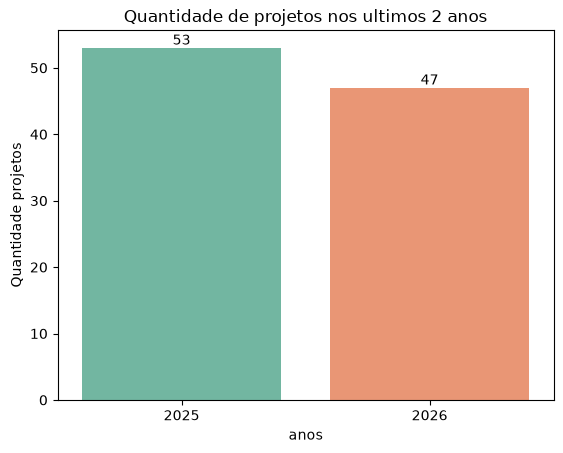

In [ ]:

# 2025
before = ly_df.shape[0]
# 2026
today = ty_df.shape[0]
ax = sns.barplot(hue=["2025", "2026"], x=["2025", "2026"], y=[before, today], palette='Set2', legend=False)
for c in ax.containers:
    ax.bar_label(c, fontsize=10)
ax.set_xlabel("anos")
ax.set_ylabel("Quantidade projetos")
plt.title("Quantidade de projetos nos ultimos 2 anos")
plt.show()

### projetos por professor

In [ ]:

prof_grouped = df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped.columns = ["professor", "quantidade_projetos"]
prof_grouped

,professor,quantidade_projetos
0,Ivan do Carmo Machado,5
1,Leobino Nascimento Sampaio,4
2,Luciano Rebouças de Oliveira,3
3,Manoel Gomes de Mendonça Neto,3
4,Marlo Vieira dos Santos e Souza,3
5,Maycon Leone Maciel Peixoto,6
6,Rafael Augusto de Melo,3
7,Ricardo Araújo Rios,10
8,Rita Suzana Pitangueira Maciel,4
9,Robespierre Dantas da Rocha Pita,4


In [64]:
nomes_abreviados = prof_grouped["professor"].str.split(" ").str[-1] + ", " + prof_grouped["professor"].str[0] + "."
nomes_abreviados = nomes_abreviados.values.tolist()
nomes_abreviados

['Machado, I.',
 'Sampaio, L.',
 'Oliveira, L.',
 'Neto, M.',
 'Souza, M.',
 'Peixoto, M.',
 'Melo, R.',
 'Rios, R.',
 'Maciel, R.',
 'Pita, R.',
 'Rios, T.']

C:\Users\ferna\AppData\Local\Temp\ipykernel_8876\1993620262.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(nomes_abreviados)


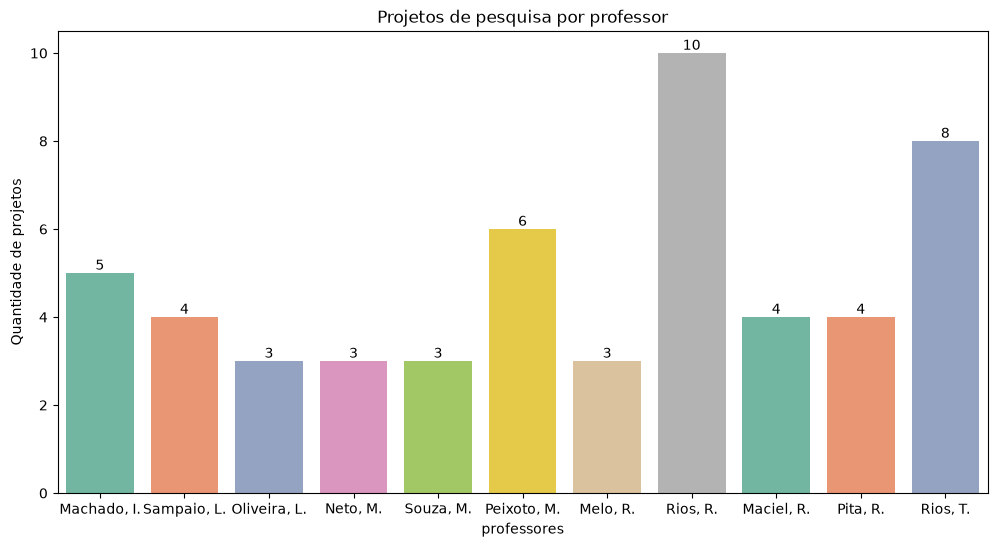

In [71]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(prof_grouped, hue="professor", x="professor", y="quantidade_projetos", palette='Set2', ax=ax)
for c in ax.containers:
    ax.bar_label(c, fontsize=10)
ax.set_xlabel("professores")
ax.set_xticklabels(nomes_abreviados)
ax.set_ylabel("Quantidade de projetos")
# plt.legend(nomes_abreviados)
plt.title("Projetos de pesquisa por professor")
plt.show()

##### por ano

In [72]:
# 2026
prof_grouped_ty = ty_df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped_ty.columns = ["professor", "quantidade_projetos"]
prof_grouped_ty

,professor,quantidade_projetos
0,Ivan do Carmo Machado,5
1,Leobino Nascimento Sampaio,2
2,Luciano Rebouças de Oliveira,3
3,Manoel Gomes de Mendonça Neto,2
4,Marlo Vieira dos Santos e Souza,3
5,Maycon Leone Maciel Peixoto,4
6,Rafael Augusto de Melo,3
7,Ricardo Araújo Rios,10
8,Rita Suzana Pitangueira Maciel,3
9,Robespierre Dantas da Rocha Pita,4


In [73]:
# 2025
prof_grouped_ly = ly_df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped_ly.columns = ["professor", "quantidade_projetos"]
prof_grouped_ly

,professor,quantidade_projetos
0,Ivan do Carmo Machado,5
1,Leobino Nascimento Sampaio,4
2,Luciano Rebouças de Oliveira,3
3,Manoel Gomes de Mendonça Neto,3
4,Marlo Vieira dos Santos e Souza,3
5,Maycon Leone Maciel Peixoto,6
6,Rafael Augusto de Melo,3
7,Ricardo Araújo Rios,10
8,Rita Suzana Pitangueira Maciel,4
9,Robespierre Dantas da Rocha Pita,4


C:\Users\ferna\AppData\Local\Temp\ipykernel_8876\737538341.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[c].set_xticklabels(nomes_abreviados)
C:\Users\ferna\AppData\Local\Temp\ipykernel_8876\737538341.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[c].set_xticklabels(nomes_abreviados)


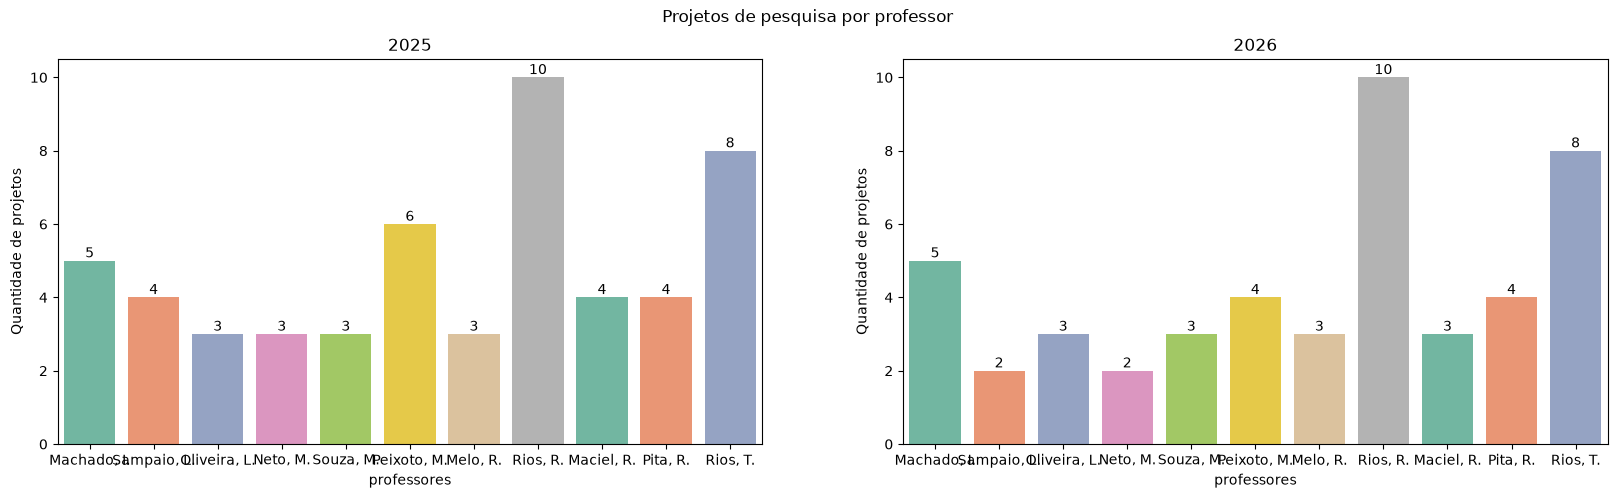

In [84]:
nrows, ncols = 1, 2
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 5))
dfs = [prof_grouped_ly, prof_grouped_ty]
titles = ["2025", "2026"]
for c in range(ncols):
    sns.barplot(dfs[c], hue="professor", x="professor", y="quantidade_projetos", palette='Set2', ax=ax[c])
    for cont in ax[c].containers:
        ax[c].bar_label(cont, fontsize=10)
    ax[c].set_title(titles[c])
    ax[c].set_xlabel("professores")
    ax[c].set_xticklabels(nomes_abreviados)
    ax[c].set_ylabel("Quantidade de projetos")

plt.suptitle("Projetos de pesquisa por professor")
plt.show()

### Orientandos

analisar quais professores possui mais orientandos em seus projetos (validar melhor estrategia para isso)

In [86]:
df.head(3)

,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,qtd_doutorado,total_alunos,edital_ou_chamada,coordenador,financiador,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Uma Investigação Empírica da Relação entre Ref...,Descrição: A temática de refatoração tem sido ...,Em andamento,Pesquisa,Mestrado acadêmico: (3) Doutorado: (4),Ivan do Carmo Machado - Coordenador / Carla Il...,...,4,7,Situação: Em andamento; Natureza: Pesquisa,Ivan do Carmo Machado,['Conselho Nacional de Desenvolvimento Científ...,Visualização de Dados e Processamento de Imagens,Refatoração de Testes,"['refatoração', 'teste de software', 'qualidad...",False,Este projeto investigará a refatoração de test...
1,4430958315746203,Ivan do Carmo Machado,2024,<NA>,Consolidação da Rede Internacional de Pesquisa...,Descrição: O objetivo do projeto é promover a ...,Em andamento,Pesquisa,Mestrado acadêmico: (26) Doutorado: (26),Ivan do Carmo Machado - Integrante / Climene L...,...,26,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4430958315746203,Ivan do Carmo Machado,2023,<NA>,Melhoria da Qualidade de Software na Perspecti...,Descrição: O projeto vista investigar test sme...,Em andamento,Pesquisa,Graduação: (2) / Mestrado acadêmico: (2) / Dou...,Ivan do Carmo Machado - Integrante / rohit Ghe...,...,6,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Financiamentos
analisar quais sao as naturezas de financiamentos
analisar se ha projetos sem financiamento
analisar 

### Linhas de pesquisa
- analisar quais sao as linhas de pesquisa
    - ha alguma(s) linha(s) de pesquisa com maior quantitativo de projetos?
- analisar se ha correlacao entre tempo medio de duracao similares entre projetos de mesma linha de pesquisa
    - com coordenador igual ou distinto
- analisar correlacao entre financiamento e linha de pesquisa: ha alguma linha que possui mais financiamento? 

### tempo de duracao
- analisar tempo de duracao dos projetos
- analisar se ha algum orientador que demore mais nos projetos

### Internacionalizacao
- checar se ha linhas de pesquisa que puxam mais internacionalizacao ou fomento de capital estrangeiro
- checar duracao: mais curta? mais demorada? similar aos "nacionais"?
- ha algum(ns) professor(es) que tem mais projetos internacionais? ha alguma correlacao?

In [87]:
columns

['lattes_id',
 'professor',
 'ano_inicio',
 'ano_conclusao',
 'projeto',
 'descricao',
 'situacao',
 'natureza',
 'alunos_envolvidos',
 'integrantes',
 'financiadores',
 'descricao_limpa',
 'qtd_graduacao',
 'qtd_mestrado',
 'qtd_doutorado',
 'total_alunos',
 'edital_ou_chamada',
 'coordenador',
 'financiador',
 'area_pgcomp',
 'topico_pesquisa',
 'palavras_chave',
 'cooperacao_internacional',
 'resumo_executivo']